In [2]:
'''
Gatlat Kulang
Godwin Wangwa
Project: Heart Disease Training
Due: 12/5/2026
'''

'\nGatlat Kulang\nGodwin Wangwa\nProject: Heart Disease Training\nDue: 12/5/2026\n'

In [13]:
#import and load data for the decision tree 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score

df=pd.read_csv("../data/heart_disease_clean.csv")
X=df.drop(columns=["target"])
y=df["target"] #1 =heart disease and 0=no heart disease

In [14]:
#define how to split the data
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

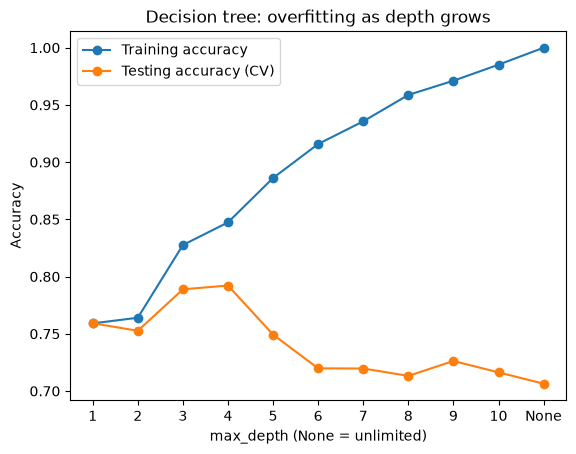

In [15]:
#overfiiting check
depths = list(range(1, 11)) + [None]
train_acc, test_acc = [], []

for d in depths:
    tree = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=0)
    scores = cross_validate(tree, X, y, cv=cv, scoring="accuracy", return_train_score=True)
    train_acc.append(scores["train_score"].mean())
    test_acc.append(scores["test_score"].mean())

labels = [str(d) for d in depths]
plt.plot(labels, train_acc, marker="o", label="Training accuracy")
plt.plot(labels, test_acc, marker="o", label="Testing accuracy (CV)")
plt.xlabel("max_depth (None = unlimited)")
plt.ylabel("Accuracy")
plt.title("Decision tree: overfitting as depth grows")
plt.legend()
plt.show()

In [16]:
#tuning 
param_grid={
    "max_depth":[2,3,4,5,6,8,None],
    "min_samples_leaf" :[1,5,10,20],
}
grid = GridSearchCV(
    DecisionTreeClassifier(criterion="entropy", random_state=0),
    param_grid, cv=cv, scoring="roc_auc"
)
grid.fit(X, y)

print("Best settings:", grid.best_params_)
print("Best CV AUROC:", round(grid.best_score_, 3))
best_tree = grid.best_estimator_

Best settings: {'max_depth': 4, 'min_samples_leaf': 20}
Best CV AUROC: 0.86


In [17]:
#final cross vaidated scores
final = cross_validate(best_tree, X, y, cv=cv, scoring=["accuracy", "roc_auc"])
print(f"Accuracy: {final['test_accuracy'].mean():.3f} ± {final['test_accuracy'].std():.3f}")
print(f"AUROC:    {final['test_roc_auc'].mean():.3f} ± {final['test_roc_auc'].std():.3f}")

Accuracy: 0.785 ± 0.024
AUROC:    0.860 ± 0.028


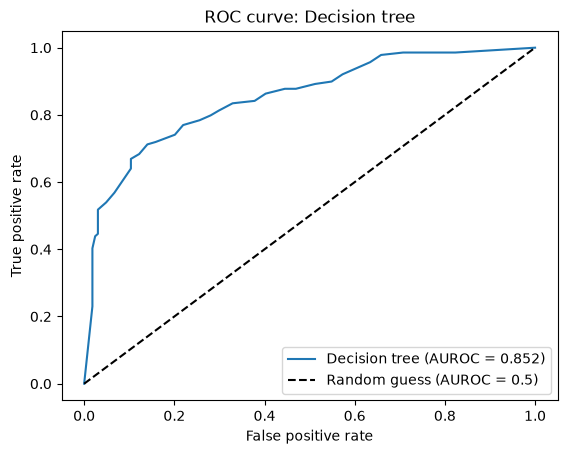

In [18]:
#Roc curve and AUROC
y_prob = cross_val_predict(best_tree, X, y, cv=cv, method="predict_proba")[:, 1]
fpr, tpr, _ = roc_curve(y, y_prob)
auroc = roc_auc_score(y, y_prob)

plt.plot(fpr, tpr, label=f"Decision tree (AUROC = {auroc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUROC = 0.5)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve: Decision tree")
plt.legend()
plt.show()

In [20]:
#feature importance for the total information gain from every split
best_tree.fit(X, y)
importances = pd.Series(best_tree.feature_importances_, index=X.columns).sort_values(ascending=False)

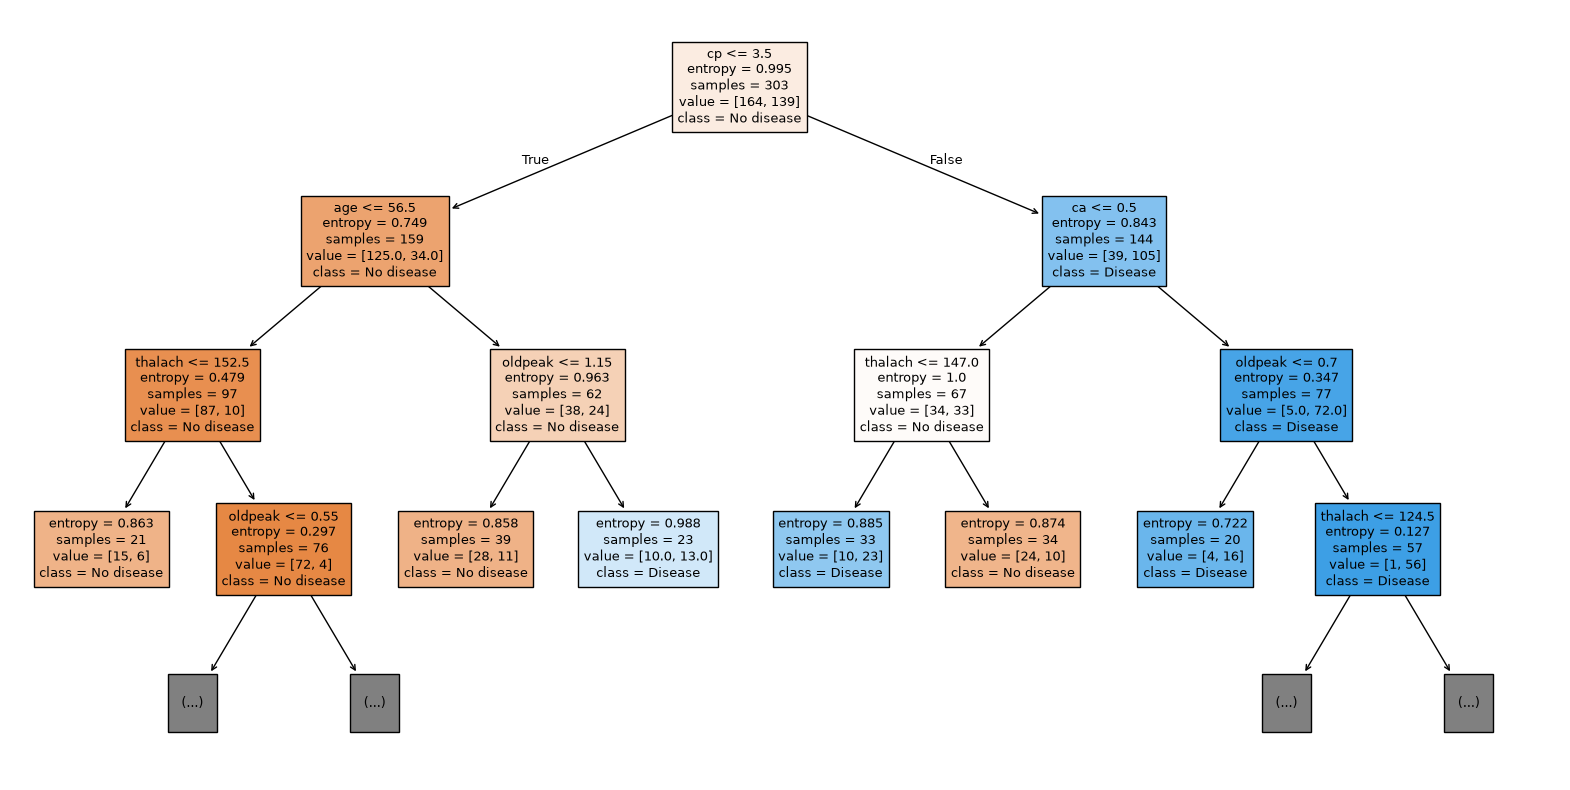

In [23]:
plt.figure(figsize=(20, 10))
plot_tree(best_tree, feature_names=list(X.columns), class_names=["No disease", "Disease"],
          filled=True, max_depth=3, fontsize=9)
plt.show()

In [25]:
# Likelihood of heart disease for the first five patients
probs = best_tree.predict_proba(X.head(5))[:, 1]
for i, p in enumerate(probs):
    print(f"Patient {i}: {p:.0%} likelihood of heart disease")

Patient 0: 57% likelihood of heart disease
Patient 1: 95% likelihood of heart disease
Patient 2: 100% likelihood of heart disease
Patient 3: 11% likelihood of heart disease
Patient 4: 11% likelihood of heart disease
